# Jour 1 : Introduction à Pandas et Analyse Exploratoire des Données (EDA)

## Documentations
- [Pandas](https://pandas.pydata.org/pandas-docs/stable/)
- [Matplotlib](https://matplotlib.org/stable/users/index.html)


## 1. Bases de Pandas
> Préparez votre IDE pour une version de Python `>=3.11` et installez `pandas`,`pandas-stubs`, `openpyxl` et `matplotlib`.

In [31]:
from fontTools.diff import color
!python --version

Python 3.14.0


In [32]:
!pip install pandas pandas-stubs openpyxl matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


> Configurez `pandas` afin que l'affichage par défaut des DataFrames affiche au
minimum 6 colonnes, au maximum 12 colonnes, au maximum 100 lignes de
contenu, au maximum 20 caractères par colonne et 240 caractères par ligne.

In [33]:
import pandas as pd
import numpy as np
# Colonnes (min 6, max 12) avec 20 caractères max pour chaque
pd.set_option('display.max_columns', 12)    # 12 colonnes max
pd.set_option('display.max_colwidth', 20)   # 20 caractères par colonne

# Lignes (max 100 lignes) avec 240 caractères max par ligne
pd.set_option('display.max_rows', 100)      # 100 lignes max
pd.set_option('display.width', 240)         # 240 caractères par ligne


# Vérifier que les modifications ont bien été prises en compte
values = ['max_columns', 'max_colwidth', 'max_rows', 'width']
for value in values:
  print(f"{value}: {pd.get_option('display.' + value)}")

max_columns: 12
max_colwidth: 20
max_rows: 100
width: 240


Il n'existe pas d'option minimal pour les colonnes à afficher, cependant on peut contrôler l'affichage des colonnes via le DataFrame directement

`display.min_columns` n'existe pas

```df[[col1, col2, col3, col4, col5, col6 ]]``` -> on force l'affichage des colonnes sélectionnées, ici 6

> Créez un DataFrame depuis des valeurs aléatoires, avec 20 colonnes et 200
lignes, et vérifiez que son affichage respecte la configuration que vous avez
établie précédemment.

In [34]:
import random, string


# Pour vérifier que la taille maximale des colonnes est respectée, on va créer une fonction créant du texte avec au minimum 20 caractères
def random_text(min_len=20, max_len=30):
    return "".join(random.choice(string.ascii_letters + string.digits) for _ in range(random.randint(min_len, max_len))) 

# Création du DataFrame
df = pd.DataFrame(
    [[random_text() for _ in range(20)] for _ in range(200)],
    columns=[f"col_{i}" for i in range(20)],
)
df

,col_0,col_1,col_2,col_3,col_4,col_5,...,col_14,col_15,col_16,col_17,col_18,col_19
0,GudQf7H82IJs8xOp...,CqefZGaMWgECb1u8...,3594RwVzdf7Dz9qp...,Y2OLPvBRO5AMvP5V...,pKUsacSxjpfRZMlL...,0boHKg6PBAo0lAv7...,...,hMQRzOt62EvRTnYo...,yq8sCacB5ad2sUxD...,KW3HfFLKEj8Q7DMI...,N22toCBLd2IIti3g...,15htECioVgenLdXr...,osf8ubVIXvu5SKO2...
1,27ubihzA9xXWm8TY...,VSuoaGKlECOyTi7v...,mQ6fkOQDtyill45q...,LMb8BjB4da5qwG9E...,Ef4uwNzDTNKdf0Y1...,7Qzz3L37F2oHwNV1...,...,9t43U63kHQk8wKt2...,kRFm3nBG0tnUqvmL...,feMtI5mGkkRCP06H...,ViSzHy9qFgMc3dyb...,xejWuQJ3Bl2KQQEn...,pCkDqmCedEa80VKM...
2,8fboG5vlTF20uS2K...,RFAJjjirIpLDkgqu...,NNU9kPkdnf8cZIJO...,L4jCZgjyKaHa11zd...,1PaEJPuennOxU0ZY...,TuF1sOg0r4sqVXE7...,...,ZH0rnQW5bcgsv7Du...,Qg8xrODVm4bLALm5...,qo1FAF7k4nrJRyln...,EF7CKNAbd6FPjAuj...,JvZw1LoW4E6keRS7...,MmG9SHBjtJEx7BOZ...
3,Oex64gTY81P6HZmD...,oRXzZjBoB5PseLDy...,rdm3f8iUjJBAjgcp...,HTStJ0WBsI6mnIVu...,XffI7B2vhgX5Sd6h...,qyfj00hbghbVRlyM...,...,uYXQjzd2jX450bZx...,UH48aRHRRlpbHnVb...,Rt9Z37RFmQLkygcV...,Ng2Qz5IRDKZWsiPi...,T3c6QxGXkru5hm9z...,DmMXw0dyXiwKtNeE...
4,UnN068mOTcY4q8o7...,TYHWg5oplFPLEKTR...,TWH4X89iiLikbs6K...,3VJM6PqOTP2o5zd8...,HK8tNMSXLXCnM3Xb...,wGALyP5j6d6OZ8BE...,...,SPuSY45Vev1ZYJfA...,0Y482g1VxmsLLK4F...,PFJrJEXY8oj6Og4y...,jceM8P0lMrFhF3Lf...,awLBAWFJy1vbBJUN...,P8uKg4lJuiulPL38...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,EPzWb8YXSQ57C05d...,p4GUTC1Wk12XsOKL...,AJDc0vq3oYAkWeyY...,RmTa9gNwuRdUdqRJ...,6vsQxFxCQutkW6lB...,wMMi4VapCZxcZc4q...,...,4lg3VAyQmdhnzlil...,2m7bgouU0wgOi8kV...,UDTDrc5Wj4sxpdbQ...,8B2hWQtpJ1J4jRws...,0g0k2Ep2N4mnRS75...,DqQZU2YT4r4FrTHj...
196,k0jI6HHF91VmlAS2...,tSiqETowJRMcT73F...,Y7Q8MB6SiSvKuEcN...,9kHnhzGKETiUVyxo...,qhEaAJbvXu7G23dj...,OW4vgGasg08WEmT2...,...,ZkX5PZJA8SAyZmDv...,mNeTUVHRCecVBCec...,5iqpFdBrGzFLUgGC...,EcwvCohjuifF62F6...,CICSKaTeTRleh4r4...,E1OpDhSY4tIQ1V1l...
197,pq5sOR9zxZNfM85O...,IWlG5iPYgW37NvsW...,EO5WqkXfFTLPQ7Wd...,LBH9hHC69nid7r1Q...,eu2TkuyEKIAgyzX8...,o8cRlryGVwQ1da8g...,...,YlUkLY9fdI1qsKDd...,9ONp2nuscILZEE9h...,vJcCidUGe1JtMPaQ...,S5x2U1KCXzB3cIhW...,JYJQJS9syYrDA5XS...,CMSmQYg2ZXYayX18...
198,g2xyMsUKcFGTDUPu...,vwER5PYWZnriQ6Jh...,KSnpmC1c1jUVvIe7...,ja5bHvnKd6HubVw0...,47mhwCkivHLkRdHa...,w6VD8qdH4IbTC8QI...,...,2nCzJtnsaSzqY7Dz...,ZBGHYCoyawfmg0tE...,JRz3K91je8qXYnMW...,uwT6H8kLsNyIlIR4...,cnr16WduZb25J87O...,p9XrCobVpESImy8c...


> Expliquez les concepts de base de Pandas, à savoir les `DataFrames` , les `Series` et les `Index`.

# Dataframes
Un `Dataframe`est un ensemble de `Series` Pandas indexées par une valeur.
C'est un tableau à 2 dimensions composés de lignes et de colonnes permettant de mettre en avant les relations entre les différentes variables du jeu de données.

Il peut contenir plusieurs type comme des nombres, du texte, des dates, etc par colonne comme une feuille Excel.

Chaque clé = nom de colonne

Chaque valeur = Series



# Series
Les `Series` sont des objets correspondants à des tableaux à une seule dimension.
C'est l'équivalent d'une seule colonne (ou ligne) avec un index.

Chaque colone de DataFrame est une Serie et associe à chaque valeur un index.


# Index
L'index est un objet contenant les étiquettes des axes (lignes et colonnes), permet d'identifier chaque ligne/colonnne et sert à aligner les données, faire des jointures etc

On peut voir l'index comme une série de données indentifiant des colonnes ou lignes

## 2. Chargement et exploration des données
> Chargez chaque feuille de calcul du fichier Excel dans des  DataFrame séparés,
> pour des variables nommées respectivement :
> - orders
> - territories
> - sales
> - resellers
> - dates
> - products
> - customers

In [35]:
# Création d'un dictionnaire global
dataframes = {}

# Stockage des noms de variables pour les différents dataframes
names = ['orders', 'territories', 'sales', 'resellers', 'dates', 'products', 'customers']

# Lecture du fichier Excel
sheets = pd.read_excel("datas/CC-AIBD-DataAnalyse-donnees.xlsx", sheet_name=None)

# Pour chaque feuille du fichier, on stocke le dataframe dans le dictionnaire global
for i, (_, df) in enumerate(sheets.items()):
    dataframes[names[i]] = df

# Exemple d'affichage d'un dataframe
dataframes['territories']

,SalesTerritoryKey,Region,Country,Group
0,1,Northwest,United States,North America
1,2,Northeast,United States,North America
2,3,Central,United States,North America
3,4,Southwest,United States,North America
4,5,Southeast,United States,North America
5,6,Canada,Canada,North America
6,7,France,France,Europe
7,8,Germany,Germany,Europe
8,9,Australia,Australia,Pacific
9,10,United Kingdom,United Kingdom,Europe


> - Affichez les cinq premières lignes de chaque  DataFrame et vérifiez-en également les types de colonnes.
> - Affichez des informations de base sur les DataFrame via les méthodes info() et describe() pour obtenir des informations sur la taille, les types de données et les valeurs manquantes dans chaque DataFrame .
> - Si besoin, notez les colonnes qui ont un type qui semble incorrect vis-à-vis de leur usage
---
-> Cf présentation pour voir l'analyse des différents dataframes dans la présentation

> - Affichez des informations de distribution (dispersion) du coût standard des produits du catalogue. Affichez la médiane, l'écart-type et la variance. 

Pour faire ça, nous allons utiliser `agg` qui va nous permettre d'appliquer une ou plusieurs fonctions d'aggrégation sur notre DataFrame ou sur un groupby afin de produire un tableau de statistiques

In [36]:
df = dataframes["products"]

stats = df["Standard Cost"].agg(["median", "std", "var"])
stats.index = ["Médiane", "Écart type", "Variance"]

stats

Médiane          204.625100
Écart type       497.076884
Variance      247085.428708
Name: Standard Cost, dtype: float64

> Calculez les mêmes informations, mais cette fois-ci par catégorie de produit (Category)

In [37]:
df = dataframes["products"]

stats = df.groupby("Category")["Standard Cost"].agg(["median", "std", "var"])
stats.columns = ["Médiane", "Écart type", "Variance"]

stats

,Médiane,Écart type,Variance
Category,,,
Accessories,11.2163,13.127986,172.344014
Bikes,713.0798,552.407211,305153.726769
Clothing,26.1763,12.424381,154.365235
Components,187.1571,280.636563,78756.880441


## 3. Nettoyage des données
> Assurez-vous dans tous les `DataFrames` qu'il n'existe aucune cellule laissée vide. Si ce n'est pas le cas, affichez les identifiants des colonnes contenant des valeurs vides. Remplacez également ces valeurs par une valeur de repli si besoin

In [38]:
# Trouver les dataframes dans lesquels au moins une cellule a une valeur manquante
dataframes_with_empty_cell = []
for key, df in dataframes.items():
    if df.isna().any().any() > 0:
        dataframes_with_empty_cell.append(key)

print(dataframes_with_empty_cell)


['sales', 'products']


In [39]:
for df in dataframes_with_empty_cell:
    # On regarde les colonnes avec des valeurs manquantes pour les df trouvés
    print(dataframes[df].isna().sum())

SalesOrderLineKey             0
ResellerKey                   0
CustomerKey                   0
ProductKey                    0
OrderDateKey                  0
DueDateKey                    0
ShipDateKey                2113
SalesTerritoryKey             0
Order Quantity                0
Unit Price                    0
Extended Amount               0
Unit Price Discount Pct       0
Product Standard Cost         0
Total Product Cost            0
Sales Amount                  0
dtype: int64
ProductKey        0
SKU               0
Product           0
Standard Cost     0
Color            56
List Price        0
Model             0
Subcategory       0
Category          0
dtype: int64


Nous trouvons ici 2 colonnes problématiques : 
- `ShipDateKey` dans le dataframe `sales`
- `Color` dans le dataframe `products`

## 3.1.1 - `ShipDateKey` dans le dataframe `sales`

Par rapport à ShipDateKey, on remarque que dans le DataFrame, il y a 3 colonnes pour les dates :
- OrderDate en int64
- DueDateKey en int64
- ShipDateKey en float64 -> Ici le type de la colonne est en float sûrement à cause des valeurs manquantes

Je choisis ici de convertir les données en Int64 pour la colonne ShipDateKey afin de garder le concept de clé en int et en rendant nulle (\<NA\>) les valeurs manquantes que je mettrais à -1 pour les ShipDateKey non définies.

Je convertis en Int64 et pas en int64 car ici la colonne peut avoir des valeurs nulles. Si je garde en int64, vu qu'il y a des valeurs manquantes, la colonne va être convertie en float64.

In [40]:
dataframes['sales'].info()

<class 'pandas.DataFrame'>
RangeIndex: 121253 entries, 0 to 121252
Data columns (total 15 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   SalesOrderLineKey        121253 non-null  int64  
 1   ResellerKey              121253 non-null  int64  
 2   CustomerKey              121253 non-null  int64  
 3   ProductKey               121253 non-null  int64  
 4   OrderDateKey             121253 non-null  int64  
 5   DueDateKey               121253 non-null  int64  
 6   ShipDateKey              119140 non-null  float64
 7   SalesTerritoryKey        121253 non-null  int64  
 8   Order Quantity           121253 non-null  int64  
 9   Unit Price               121253 non-null  float64
 10  Extended Amount          121253 non-null  float64
 11  Unit Price Discount Pct  121253 non-null  int64  
 12  Product Standard Cost    121253 non-null  float64
 13  Total Product Cost       121253 non-null  float64
 14  Sales Amount   

In [41]:
dataframes['sales']['ShipDateKey'] = dataframes['sales']['ShipDateKey'].astype("Int64")
dataframes['sales']['ShipDateKey'] = dataframes['sales']['ShipDateKey'].fillna(-1)

## 3.1.2 - `Color` dans le dataframe `products`

Ici, les valeurs nulles sont les couleurs des produits.

Je décide juste de remplacer NA par "Default" pour les couleurs nulles dans mon DataFrame.

In [42]:
dataframes['products'].info()

<class 'pandas.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ProductKey     397 non-null    int64  
 1   SKU            397 non-null    str    
 2   Product        397 non-null    str    
 3   Standard Cost  397 non-null    float64
 4   Color          341 non-null    str    
 5   List Price     397 non-null    float64
 6   Model          397 non-null    str    
 7   Subcategory    397 non-null    str    
 8   Category       397 non-null    str    
dtypes: float64(2), int64(1), str(6)
memory usage: 28.0 KB


In [43]:
dataframes['products']['Color'].fillna("Default", inplace=True)

C:\Users\alguy\AppData\Local\Temp\ipykernel_5280\430288213.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  dataframes['products']['Color'].fillna("Default", inplace=True)


0        Black
1          Red
2          Red
3          Red
4          Red
        ...   
392    Default
393    Default
394      Black
395      Black
396      Black
Name: Color, Length: 397, dtype: str

In [44]:
dataframes['products'].info()

<class 'pandas.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ProductKey     397 non-null    int64  
 1   SKU            397 non-null    str    
 2   Product        397 non-null    str    
 3   Standard Cost  397 non-null    float64
 4   Color          341 non-null    str    
 5   List Price     397 non-null    float64
 6   Model          397 non-null    str    
 7   Subcategory    397 non-null    str    
 8   Category       397 non-null    str    
dtypes: float64(2), int64(1), str(6)
memory usage: 28.0 KB


In [45]:
# Vérification de la présence de valeurs nulles
for df in dataframes_with_empty_cell:
    # On regarde les colonnes avec des valeurs manquantes pour les df trouvés
    print(dataframes[df].isna().sum())

SalesOrderLineKey          0
ResellerKey                0
CustomerKey                0
ProductKey                 0
OrderDateKey               0
DueDateKey                 0
ShipDateKey                0
SalesTerritoryKey          0
Order Quantity             0
Unit Price                 0
Extended Amount            0
Unit Price Discount Pct    0
Product Standard Cost      0
Total Product Cost         0
Sales Amount               0
dtype: int64
ProductKey        0
SKU               0
Product           0
Standard Cost     0
Color            56
List Price        0
Model             0
Subcategory       0
Category          0
dtype: int64


> Vérifiez dans les ventes que le total des ventes est correct, notamment lorsque la valeur de remise (discount) est non nulle.


In [46]:
df_sales = dataframes['sales']
df_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 121253 entries, 0 to 121252
Data columns (total 15 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   SalesOrderLineKey        121253 non-null  int64  
 1   ResellerKey              121253 non-null  int64  
 2   CustomerKey              121253 non-null  int64  
 3   ProductKey               121253 non-null  int64  
 4   OrderDateKey             121253 non-null  int64  
 5   DueDateKey               121253 non-null  int64  
 6   ShipDateKey              121253 non-null  Int64  
 7   SalesTerritoryKey        121253 non-null  int64  
 8   Order Quantity           121253 non-null  int64  
 9   Unit Price               121253 non-null  float64
 10  Extended Amount          121253 non-null  float64
 11  Unit Price Discount Pct  121253 non-null  int64  
 12  Product Standard Cost    121253 non-null  float64
 13  Total Product Cost       121253 non-null  float64
 14  Sales Amount   

On nous demande ici de vérifier dans les ventes que le total des ventes est correct surtout si la valeur de remise est non null.
Tout d'abord, nous vérifions que le colonne n'a pas de remise null et nous allons effectuer les différents contrôles par la suite.

In [47]:
# On vérifie que la colonne n'a pas de remise nulle
df_discount_not_null = df_sales["Unit Price Discount Pct"].isna()

# On vérifie que toutes les lignes ont une remise définie
df_discount_not_null.sum()

# np.int64(0) -> Aucune valeur nulle trouvée dans cette colonne

np.int64(0)

### Contrôle du montant avant remise

In [48]:
tolerance = 0.01 # Nous tolérons ici que 1 centime d'écart max

# Contrôle du montant avant remise
df_sales["Expected Extended Amount"] = df_sales["Order Quantity"] * df_sales["Unit Price"]
df_sales["Valid Extended Amount"] = np.isclose(
    df_sales["Extended Amount"],
    df_sales["Expected Extended Amount"],
    atol=tolerance
)

# Si True dans Valid Extended Amount, la valeur attendue est correcte

df_sales

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,...,Unit Price Discount Pct,Product Standard Cost,Total Product Cost,Sales Amount,Expected Extended Amount,Valid Extended Amount
0,43659001,676,-1,349,20170702,20170712,...,0,1898.0944,1898.0944,2024.994,2024.994,True
1,43659002,676,-1,350,20170702,20170712,...,0,1898.0944,5694.2832,6074.982,6074.982,True
2,43659003,676,-1,351,20170702,20170712,...,0,1898.0944,1898.0944,2024.994,2024.994,True
3,43659004,676,-1,344,20170702,20170712,...,0,1912.1544,1912.1544,2039.994,2039.994,True
4,43659005,676,-1,345,20170702,20170712,...,0,1912.1544,1912.1544,2039.994,2039.994,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121248,75122001,-1,15868,485,20200615,20200625,...,0,8.2205,8.2205,21.980,21.980,True
121249,75122002,-1,15868,225,20200615,20200625,...,0,6.9223,6.9223,8.990,8.990,True
121250,75123001,-1,18759,485,20200615,20200625,...,0,8.2205,8.2205,21.980,21.980,True
121251,75123002,-1,18759,486,20200615,20200625,...,0,59.4660,59.4660,159.000,159.000,True


### Contrôle du montant après remise

In [49]:
# Contrôle du montant avant remise
df_sales["Expected Sales Amount"] = df_sales["Order Quantity"] * df_sales["Unit Price"] * (1 - df_sales["Unit Price Discount Pct"] / 100)
df_sales["Valid Sales Amount"] = np.isclose(
    df_sales["Sales Amount"],
    df_sales["Expected Sales Amount"],
    atol=tolerance
)

# Si True dans Valid Sales Amount, la valeur attendue est correcte

df_sales

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,...,Total Product Cost,Sales Amount,Expected Extended Amount,Valid Extended Amount,Expected Sales Amount,Valid Sales Amount
0,43659001,676,-1,349,20170702,20170712,...,1898.0944,2024.994,2024.994,True,2024.994,True
1,43659002,676,-1,350,20170702,20170712,...,5694.2832,6074.982,6074.982,True,6074.982,True
2,43659003,676,-1,351,20170702,20170712,...,1898.0944,2024.994,2024.994,True,2024.994,True
3,43659004,676,-1,344,20170702,20170712,...,1912.1544,2039.994,2039.994,True,2039.994,True
4,43659005,676,-1,345,20170702,20170712,...,1912.1544,2039.994,2039.994,True,2039.994,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121248,75122001,-1,15868,485,20200615,20200625,...,8.2205,21.980,21.980,True,21.980,True
121249,75122002,-1,15868,225,20200615,20200625,...,6.9223,8.990,8.990,True,8.990,True
121250,75123001,-1,18759,485,20200615,20200625,...,8.2205,21.980,21.980,True,21.980,True
121251,75123002,-1,18759,486,20200615,20200625,...,59.4660,159.000,159.000,True,159.000,True


### Contrôle du coût total

In [50]:
# Contrôle du coût total
df_sales["Expected Total Product Cost"] = df_sales["Order Quantity"] * df_sales["Product Standard Cost"]
df_sales["Valid Total Product Cost"] = np.isclose(
    df_sales["Total Product Cost"],
    df_sales["Expected Total Product Cost"],
    atol=tolerance
)

# Si True dans Valid Total Product Cost, la valeur attendue est correcte

df_sales

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,...,Expected Extended Amount,Valid Extended Amount,Expected Sales Amount,Valid Sales Amount,Expected Total Product Cost,Valid Total Product Cost
0,43659001,676,-1,349,20170702,20170712,...,2024.994,True,2024.994,True,1898.0944,True
1,43659002,676,-1,350,20170702,20170712,...,6074.982,True,6074.982,True,5694.2832,True
2,43659003,676,-1,351,20170702,20170712,...,2024.994,True,2024.994,True,1898.0944,True
3,43659004,676,-1,344,20170702,20170712,...,2039.994,True,2039.994,True,1912.1544,True
4,43659005,676,-1,345,20170702,20170712,...,2039.994,True,2039.994,True,1912.1544,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121248,75122001,-1,15868,485,20200615,20200625,...,21.980,True,21.980,True,8.2205,True
121249,75122002,-1,15868,225,20200615,20200625,...,8.990,True,8.990,True,6.9223,True
121250,75123001,-1,18759,485,20200615,20200625,...,21.980,True,21.980,True,8.2205,True
121251,75123002,-1,18759,486,20200615,20200625,...,159.000,True,159.000,True,59.4660,True


### Vérification globale

In [51]:
# On affiche les lignes problématiques

erreurs = df_sales.loc[
    ~(df_sales["Valid Extended Amount"]
      & df_sales["Valid Sales Amount"]
      & df_sales["Valid Total Product Cost"]      
      )
]

print(f"Nombre de lignes incorrectes : {len(erreurs)}")

# erreurs[["Order Quantity", "Unit Price", "Extended Amount", "Unit Price Discount Pct", "Sales Amount", "Valid Extended Amount", "Valid Sales Amount", "Valid Total Product Cost"]]
erreurs[["Sales Amount",  "Unit Price Discount Pct", "Expected Sales Amount", "Valid Sales Amount"]]

Nombre de lignes incorrectes : 3282


,Sales Amount,Unit Price Discount Pct,Expected Sales Amount,Valid Sales Amount
656,23190.6518,0,23663.9304,False
658,24938.4761,0,25447.4246,False
713,63.8733,0,65.1768,False
734,104.2388,0,109.7250,False
769,27055.7604,0,27607.9188,False
...,...,...,...,...
60808,54.2254,0,55.3320,False
60821,135.5976,0,225.9960,False
60822,135.5976,0,225.9960,False
60835,548.5466,0,577.4175,False


Nous observons que 3282 lignes semblent ne pas avoir le résultat attendu pour le Sales Amount 

> Créez une colonne  Price ratio calculant le multiplicateur entre le prix affiché et le coût du produit.


Ici le ratio correspond au rapport entre le prix de vente unitaire et le coût unitaire du produit.
Un produit coûtant 100€ et vendu à 150€ a son ratio égal à 1.5

In [52]:
df_sales["Price ratio"] = (
    df_sales["Unit Price"]
    .div(df_sales["Product Standard Cost"].replace(0, np.nan))
    .round(2)
)

df_sales.head(10)

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,...,Valid Extended Amount,Expected Sales Amount,Valid Sales Amount,Expected Total Product Cost,Valid Total Product Cost,Price ratio
0,43659001,676,-1,349,20170702,20170712,...,True,2024.9940,True,1898.0944,True,1.07
1,43659002,676,-1,350,20170702,20170712,...,True,6074.9820,True,5694.2832,True,1.07
2,43659003,676,-1,351,20170702,20170712,...,True,2024.9940,True,1898.0944,True,1.07
3,43659004,676,-1,344,20170702,20170712,...,True,2039.9940,True,1912.1544,True,1.07
4,43659005,676,-1,345,20170702,20170712,...,True,2039.9940,True,1912.1544,True,1.07
5,43659006,676,-1,346,20170702,20170712,...,True,4079.9880,True,3824.3088,True,1.07
6,43659007,676,-1,347,20170702,20170712,...,True,2039.9940,True,1912.1544,True,1.07
7,43659008,676,-1,229,20170702,20170712,...,True,86.5212,True,95.1732,True,0.91
8,43659009,676,-1,235,20170702,20170712,...,True,28.8404,True,31.7244,True,0.91
9,43659010,676,-1,218,20170702,20170712,...,True,34.2000,True,20.3778,True,1.68


> Créez une colonne Line number dans orders extrayant le numéro de ligne de la colonne Sales Order Line .

In [53]:
df_orders = dataframes['orders']

df_orders

,Channel,SalesOrderLineKey,Sales Order,Sales Order Line
0,Reseller,43659001,SO43659,SO43659 - 1
1,Reseller,43659002,SO43659,SO43659 - 2
2,Reseller,43659003,SO43659,SO43659 - 3
3,Reseller,43659004,SO43659,SO43659 - 4
4,Reseller,43659005,SO43659,SO43659 - 5
...,...,...,...,...
121248,Internet,75122001,SO75122,SO75122 - 1
121249,Internet,75122002,SO75122,SO75122 - 2
121250,Internet,75123001,SO75123,SO75123 - 1
121251,Internet,75123002,SO75123,SO75123 - 2


In [54]:
df_orders["Line number"] = (
    df_orders["Sales Order Line"]
    .str.split(" - ")
    .str[-1]
    .astype(int)
)
df_orders

,Channel,SalesOrderLineKey,Sales Order,Sales Order Line,Line number
0,Reseller,43659001,SO43659,SO43659 - 1,1
1,Reseller,43659002,SO43659,SO43659 - 2,2
2,Reseller,43659003,SO43659,SO43659 - 3,3
3,Reseller,43659004,SO43659,SO43659 - 4,4
4,Reseller,43659005,SO43659,SO43659 - 5,5
...,...,...,...,...,...
121248,Internet,75122001,SO75122,SO75122 - 1,1
121249,Internet,75122002,SO75122,SO75122 - 2,2
121250,Internet,75123001,SO75123,SO75123 - 1,1
121251,Internet,75123002,SO75123,SO75123 - 2,2


> Traitez et convertissez les colonnes qui ne semblent pas avoir un type de données correct inféré pour l'analyse

In [55]:
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 121253 entries, 0 to 121252
Data columns (total 5 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   Channel            121253 non-null  str  
 1   SalesOrderLineKey  121253 non-null  int64
 2   Sales Order        121253 non-null  str  
 3   Sales Order Line   121253 non-null  str  
 4   Line number        121253 non-null  int64
dtypes: int64(2), str(3)
memory usage: 4.6 MB


Les types des colonnes sont déjà bien pour l'analyse.

> Créez une colonne Margin représentant la marge entre les ventes et le coût total.

In [56]:
df_sales["Margin"] = (df_sales["Sales Amount"] - df_sales["Total Product Cost"]).round(2)
df_sales

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,...,Expected Sales Amount,Valid Sales Amount,Expected Total Product Cost,Valid Total Product Cost,Price ratio,Margin
0,43659001,676,-1,349,20170702,20170712,...,2024.994,True,1898.0944,True,1.07,126.90
1,43659002,676,-1,350,20170702,20170712,...,6074.982,True,5694.2832,True,1.07,380.70
2,43659003,676,-1,351,20170702,20170712,...,2024.994,True,1898.0944,True,1.07,126.90
3,43659004,676,-1,344,20170702,20170712,...,2039.994,True,1912.1544,True,1.07,127.84
4,43659005,676,-1,345,20170702,20170712,...,2039.994,True,1912.1544,True,1.07,127.84
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121248,75122001,-1,15868,485,20200615,20200625,...,21.980,True,8.2205,True,2.67,13.76
121249,75122002,-1,15868,225,20200615,20200625,...,8.990,True,6.9223,True,1.30,2.07
121250,75123001,-1,18759,485,20200615,20200625,...,21.980,True,8.2205,True,2.67,13.76
121251,75123002,-1,18759,486,20200615,20200625,...,159.000,True,59.4660,True,2.67,99.53


Si Margin est positif -> vente rentable

Si Margin = 0 -> vente au prix coûtant

Si Margin est négatif -> vente non rentable

## 4. Analyse exploratoire des données
> Affichez le total des ventes, réparti par territoire en utilisant des graphiques à
barres.
>
> L'intitulé des barres doit être horizontal, et représenter le Country du
territoire ainsi que la Region sur une seconde ligne.
>
> Sauvegardez le diagramme dans un fichier au format PNG.


In [60]:
df_territories = dataframes["territories"]
df_territories

,SalesTerritoryKey,Region,Country,Group
0,1,Northwest,United States,North America
1,2,Northeast,United States,North America
2,3,Central,United States,North America
3,4,Southwest,United States,North America
4,5,Southeast,United States,North America
5,6,Canada,Canada,North America
6,7,France,France,Europe
7,8,Germany,Germany,Europe
8,9,Australia,Australia,Pacific
9,10,United Kingdom,United Kingdom,Europe


In [65]:
# On fusionne les 2 dataframes pour avoir les données de territoire avec les données de la vente
df_sales_territories = df_sales.merge(
    df_territories[["SalesTerritoryKey", "Country", "Group", "Region"]],
    left_on="SalesTerritoryKey",
    right_on="SalesTerritoryKey",
    how="left"
)

df_sales_territories[["SalesTerritoryKey", "Country", "Group", "Region"]]

,SalesTerritoryKey,Country,Group,Region
0,5,United States,North America,Southeast
1,5,United States,North America,Southeast
2,5,United States,North America,Southeast
3,5,United States,North America,Southeast
4,5,United States,North America,Southeast
...,...,...,...,...
121248,6,Canada,North America,Canada
121249,6,Canada,North America,Canada
121250,6,Canada,North America,Canada
121251,6,Canada,North America,Canada


In [66]:
df_sales_territories.info()

<class 'pandas.DataFrame'>
RangeIndex: 121253 entries, 0 to 121252
Data columns (total 26 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   SalesOrderLineKey            121253 non-null  int64  
 1   ResellerKey                  121253 non-null  int64  
 2   CustomerKey                  121253 non-null  int64  
 3   ProductKey                   121253 non-null  int64  
 4   OrderDateKey                 121253 non-null  int64  
 5   DueDateKey                   121253 non-null  int64  
 6   ShipDateKey                  121253 non-null  Int64  
 7   SalesTerritoryKey            121253 non-null  int64  
 8   Order Quantity               121253 non-null  int64  
 9   Unit Price                   121253 non-null  float64
 10  Extended Amount              121253 non-null  float64
 11  Unit Price Discount Pct      121253 non-null  int64  
 12  Product Standard Cost        121253 non-null  float64
 13  Total Prod

In [68]:
# L'intitulé des barres doit être horizontal, et représenter le Country du territoire ainsi que la Region sur une seconde ligne.
df_sales_territories["Territory Label"] = df_sales_territories["Country"] + "\n" + df_sales_territories["Region"]

# Calcul des totaux des ventes par territoire
sales_for_each_territory = df_sales_territories.groupby("Territory Label", as_index=False)["Sales Amount"].sum().sort_values("Sales Amount", ascending=True)

sales_for_each_territory

,Territory Label,Sales Amount
3,Germany\nGermany,4.878300e+06
6,United States\nN...,6.939374e+06
2,France\nFrance,7.251556e+06
4,United Kingdom\n...,7.670721e+06
8,United States\nS...,7.879655e+06
5,United States\nC...,7.909009e+06
0,Australia\nAustr...,1.065534e+07
7,United States\nN...,1.608494e+07
1,Canada\nCanada,1.635577e+07
9,United States\nS...,2.418461e+07


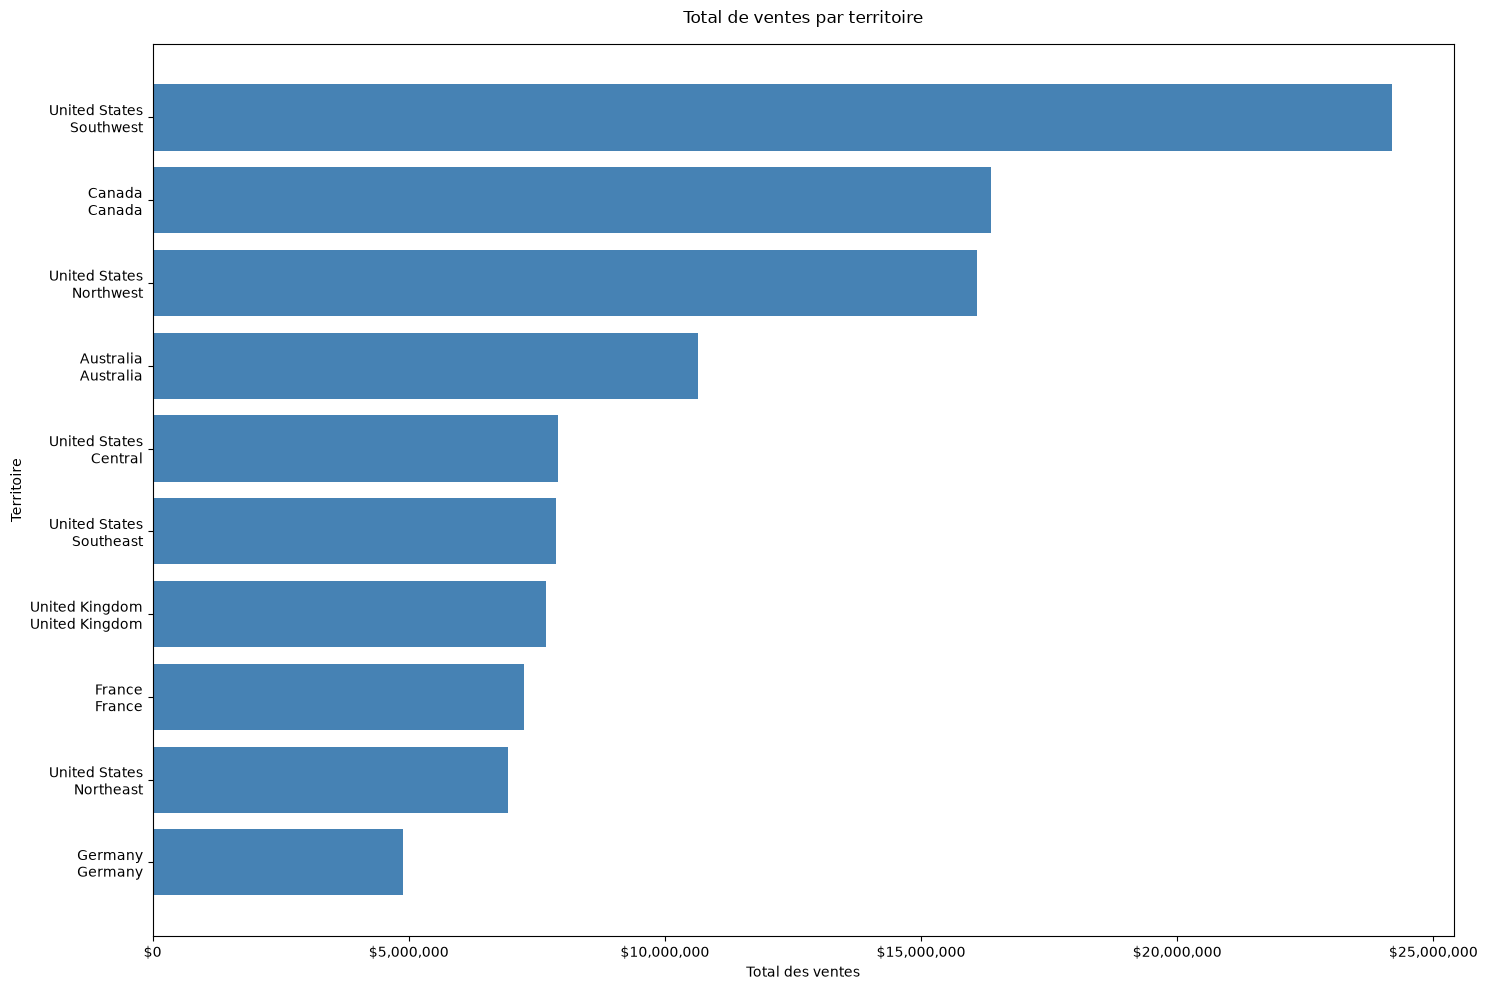

In [76]:
import matplotlib.pyplot as plt
import matplotlib.ticker as tick


# Création du graphique
fig, ax = plt.subplots(figsize=(15,10))

# Définition des axes de notre graphique
ax.barh(sales_for_each_territory["Territory Label"], sales_for_each_territory["Sales Amount"], color="steelblue")

# Paramètres du graphique
ax.set_title("Total de ventes par territoire", pad=15) # Titre du graphique
ax.set_xlabel("Total des ventes") # Label des x
ax.set_ylabel("Territoire")       # Label des y

# Formattage de la valeur des ventes
ax.xaxis.set_major_formatter(tick.StrMethodFormatter("${x:,.0f}"))

# Ajustement auto des marges
plt.tight_layout()

# Sauvegarde
plt.savefig("./output/EDA/total_ventes_par_territoire.png", dpi=300, bbox_inches="tight")
plt.show()

> Affichez le total des ventes par Model de produit via une visualisation dans un
graphique adapté (secteur ou barres).
>
> Sauvegardez également le diagramme
dans un fichier au format PNG.

Je préfère choisir ici le graphique à barres, plus lisible même s'il y a de nombreux modèles.

In [77]:
df_products = dataframes["products"]
df_products

,ProductKey,SKU,Product,Standard Cost,Color,List Price,Model,Subcategory,Category
0,210,FR-R92B-58,HL Road Frame - ...,868.6342,Black,1431.5000,HL Road Frame,Road Frames,Components
1,211,FR-R92R-58,HL Road Frame - ...,868.6342,Red,1431.5000,HL Road Frame,Road Frames,Components
2,212,HL-U509-R,Sport-100 Helmet...,12.0278,Red,33.6442,Sport-100,Helmets,Accessories
3,213,HL-U509-R,Sport-100 Helmet...,13.8782,Red,33.6442,Sport-100,Helmets,Accessories
4,214,HL-U509-R,Sport-100 Helmet...,13.0863,Red,34.9900,Sport-100,Helmets,Accessories
...,...,...,...,...,...,...,...,...,...
392,602,BB-8107,ML Bottom Bracket,44.9506,NaN,101.2400,ML Bottom Bracket,Bottom Brackets,Components
393,603,BB-9108,HL Bottom Bracket,53.9416,NaN,121.4900,HL Bottom Bracket,Bottom Brackets,Components
394,604,BK-R19B-44,"Road-750 Black, 44",343.6496,Black,539.9900,Road-750,Road Bikes,Bikes
395,605,BK-R19B-48,"Road-750 Black, 48",343.6496,Black,539.9900,Road-750,Road Bikes,Bikes


In [79]:
# On fusionne les 2 dataframes pour avoir les données de modèles avec les données de la vente
df_sales_products = df_sales.merge(
    df_products[["ProductKey", "Model"]],
    left_on="ProductKey",
    right_on="ProductKey",
    how="left"
)

df_sales_products[["ProductKey", "Model", "Sales Amount"]]

,ProductKey,Model,Sales Amount
0,349,Mountain-100,2024.994
1,350,Mountain-100,6074.982
2,351,Mountain-100,2024.994
3,344,Mountain-100,2039.994
4,345,Mountain-100,2039.994
...,...,...,...
121248,485,Fender Set - Mou...,21.980
121249,225,Cycling Cap,8.990
121250,485,Fender Set - Mou...,21.980
121251,486,All-Purpose Bike...,159.000


In [87]:
# Calcul des totaux des ventes par modèle
sales_for_each_model = (df_sales_products
                        .dropna(subset=["Model"]) # Retire les lignes où la colonne Model est vide
                        .groupby("Model", as_index=False)["Sales Amount"]
                        .sum()
                        .sort_values("Sales Amount", ascending=True))

sales_for_each_model

,Model,Sales Amount
49,LL Road Seat/Sad...,1.627200e+02
53,LL Touring Seat/...,1.480752e+03
52,LL Touring Handl...,1.548624e+03
37,LL Headset,1.949400e+03
71,ML Touring Seat/...,1.972656e+03
...,...,...
94,Road-650,8.087521e+06
101,Touring-1000,9.715802e+06
78,Mountain-100,9.910079e+06
90,Road-250,1.382872e+07


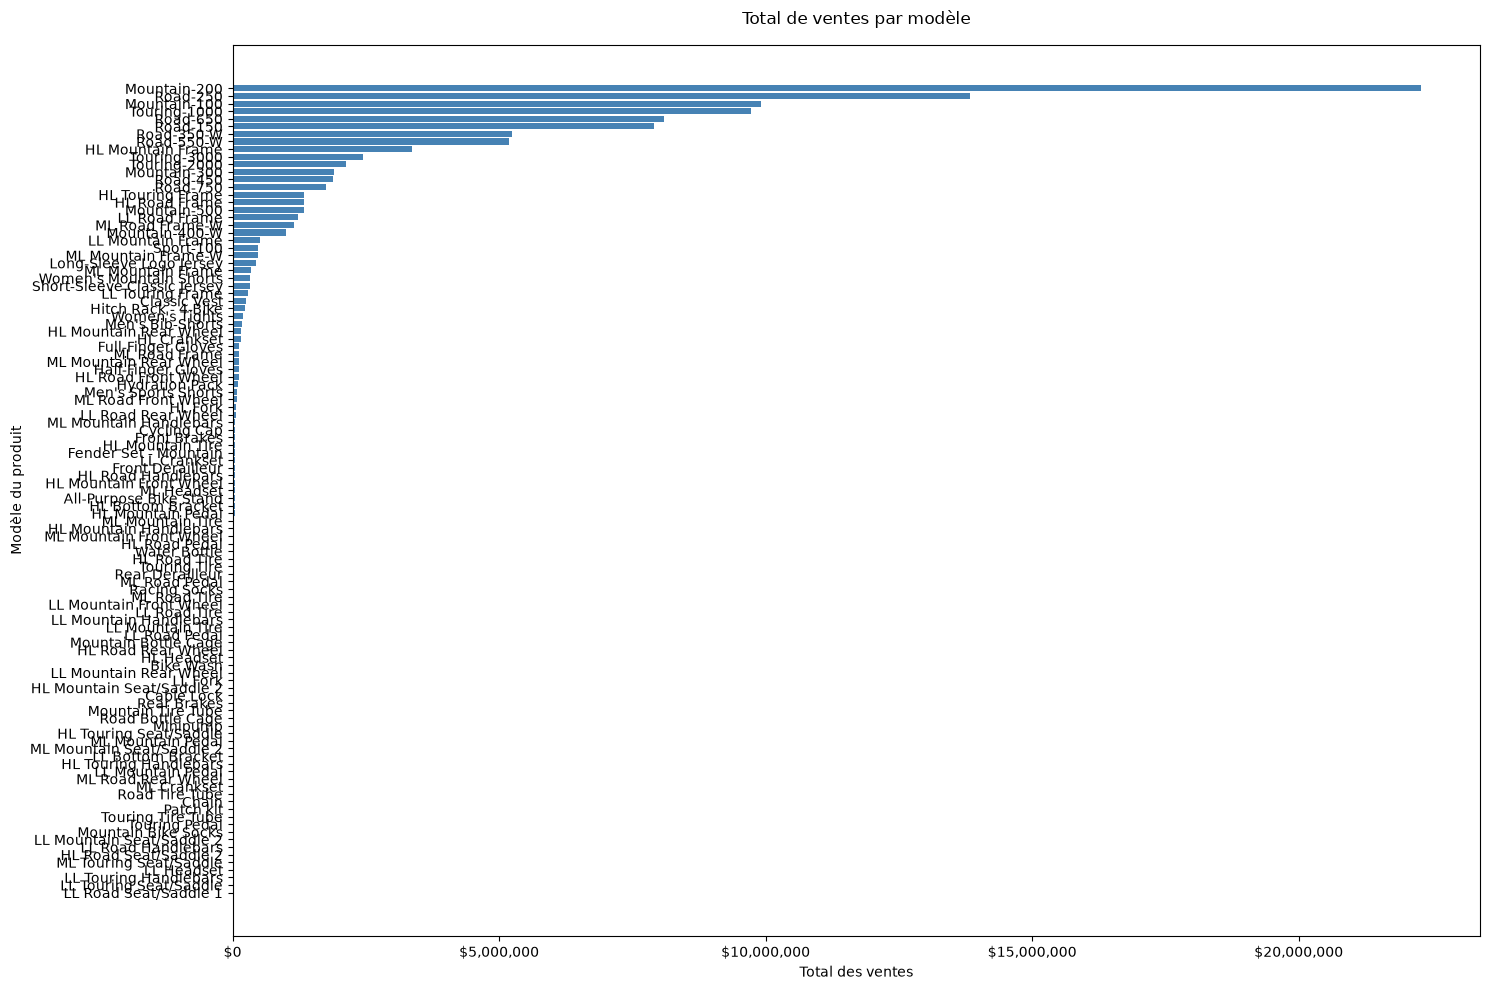

In [90]:
# Création du graphique
fig, ax = plt.subplots(figsize=(15,10))

# Définition des axes de notre graphique
ax.barh(sales_for_each_model["Model"], sales_for_each_model["Sales Amount"], color="steelblue")

# Paramètres du graphique
ax.set_title("Total de ventes par modèle", pad=15) # Titre du graphique
ax.set_xlabel("Total des ventes")        # Label des x
ax.set_ylabel("Modèle du produit")       # Label des y

# Formattage de la valeur des ventes
ax.xaxis.set_major_formatter(tick.StrMethodFormatter("${x:,.0f}"))

# Ajustement auto des marges
plt.tight_layout()

# Sauvegarde
plt.savefig("./output/EDA/total_ventes_par_modele.png", dpi=300, bbox_inches="tight")
plt.show()

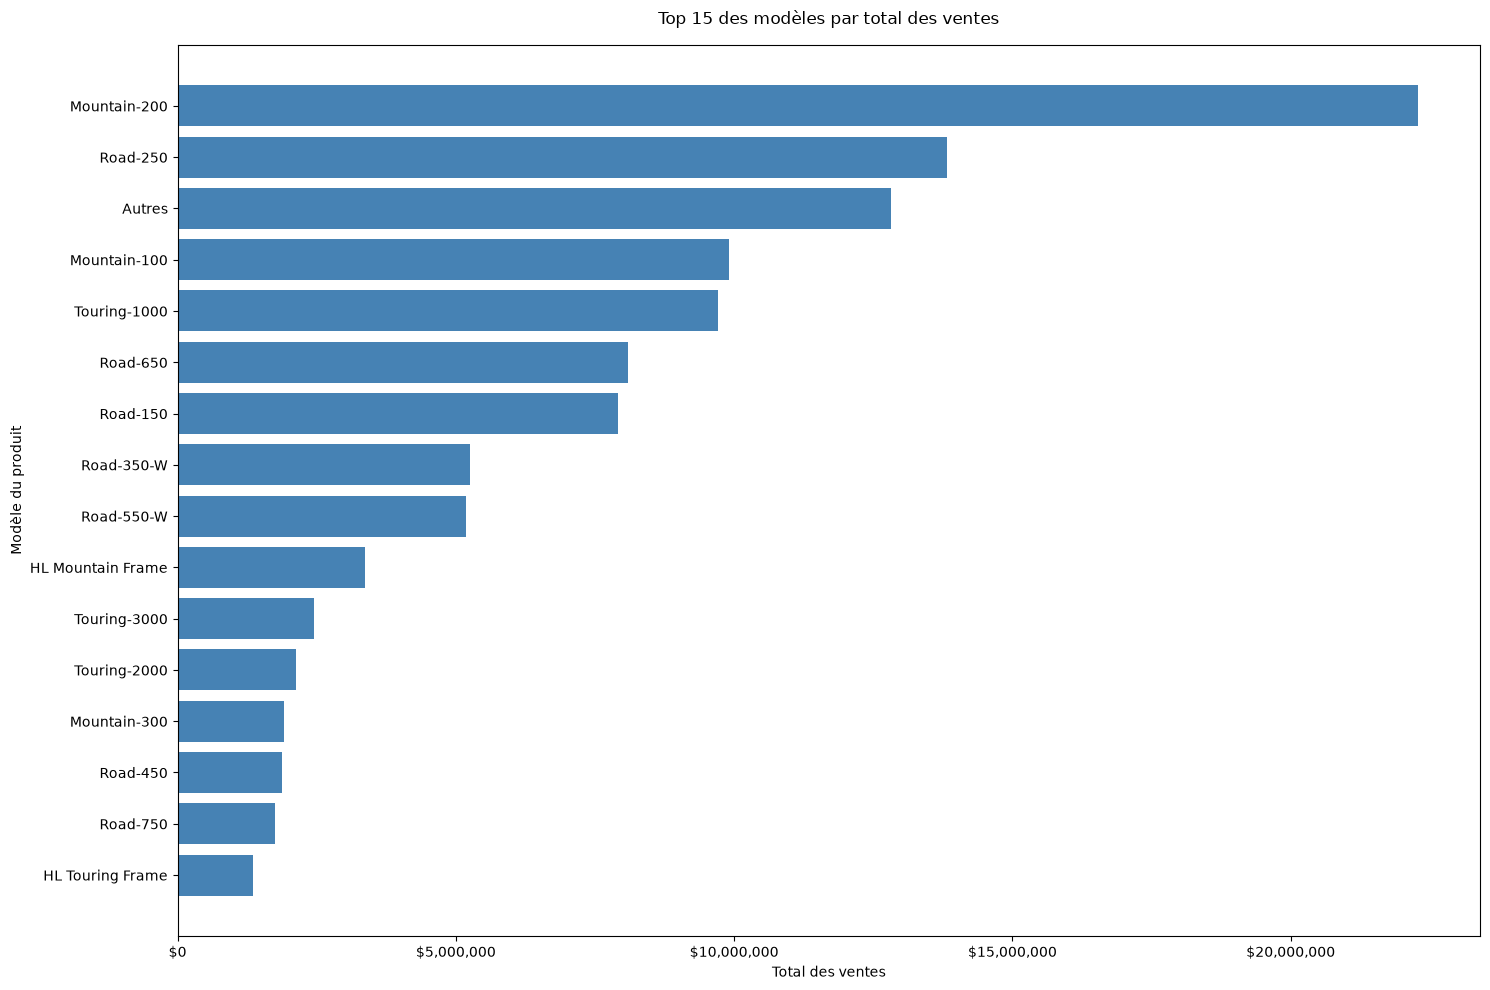

In [92]:
# Voyons voir le top 15 des ventes par modèle
n_models = 15

sales_for_each_model_sorted = sales_for_each_model.sort_values("Sales Amount", ascending=False)

# Le top 15
top_models = sales_for_each_model_sorted.head(n_models).copy()

# Le reste
others_sales = sales_for_each_model_sorted.iloc[n_models:]["Sales Amount"].sum()

if others_sales > 0 : # Ajout dans le graphique si elle est > à 0
    top_models.loc[len(top_models)] = ["Autres", others_sales]

data_sorted = top_models.sort_values(
    "Sales Amount",
    ascending=True
)

# Création du graphique
fig, ax = plt.subplots(figsize=(15,10))

# Définition des axes de notre graphique
ax.barh(data_sorted["Model"], data_sorted["Sales Amount"], color="steelblue")

# Paramètres du graphique
ax.set_title("Top 15 des modèles par total des ventes", pad=15) # Titre du graphique
ax.set_xlabel("Total des ventes")        # Label des x
ax.set_ylabel("Modèle du produit")       # Label des y

# Formattage de la valeur des ventes
ax.xaxis.set_major_formatter(tick.StrMethodFormatter("${x:,.0f}"))

# Ajustement auto des marges
plt.tight_layout()

# Sauvegarde
plt.savefig("./output/EDA/top_15_ventes_par_modele.png", dpi=300, bbox_inches="tight")

# Affichage
plt.show()

> Explorez les ventes par jour et identifiez les tendances saisonnières
potentielles;
>
> créez des colonnes avec des moyennes de ventes lissées sur 7, et
sur 30 jours.
>
> Affichez des graphiques en lignes pour voir ces tendances.

In [93]:
df_dates = dataframes["dates"]
df_dates

,DateKey,Date,Fiscal Year,Fiscal Quarter,Month,Full Date,MonthKey
0,20170701,2017-07-01,FY2018,FY2018 Q1,2017 Jul,"2017 Jul, 01",201707
1,20170702,2017-07-02,FY2018,FY2018 Q1,2017 Jul,"2017 Jul, 02",201707
2,20170703,2017-07-03,FY2018,FY2018 Q1,2017 Jul,"2017 Jul, 03",201707
3,20170704,2017-07-04,FY2018,FY2018 Q1,2017 Jul,"2017 Jul, 04",201707
4,20170705,2017-07-05,FY2018,FY2018 Q1,2017 Jul,"2017 Jul, 05",201707
...,...,...,...,...,...,...,...
1456,20210626,2021-06-26,FY2021,FY2021 Q4,2021 Jun,"2021 Jun, 26",202106
1457,20210627,2021-06-27,FY2021,FY2021 Q4,2021 Jun,"2021 Jun, 27",202106
1458,20210628,2021-06-28,FY2021,FY2021 Q4,2021 Jun,"2021 Jun, 28",202106
1459,20210629,2021-06-29,FY2021,FY2021 Q4,2021 Jun,"2021 Jun, 29",202106


In [94]:
# On fusionne les 2 dataframes pour avoir les données de la date avec les données de la vente
df_sales_dates = df_sales.merge(
    df_dates[["DateKey", "Full Date", "Date"]],
    left_on="OrderDateKey",
    right_on="DateKey",
    how="left"
)

df_sales_dates

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,...,Valid Total Product Cost,Price ratio,Margin,DateKey,Full Date,Date
0,43659001,676,-1,349,20170702,20170712,...,True,1.07,126.90,20170702,"2017 Jul, 02",2017-07-02
1,43659002,676,-1,350,20170702,20170712,...,True,1.07,380.70,20170702,"2017 Jul, 02",2017-07-02
2,43659003,676,-1,351,20170702,20170712,...,True,1.07,126.90,20170702,"2017 Jul, 02",2017-07-02
3,43659004,676,-1,344,20170702,20170712,...,True,1.07,127.84,20170702,"2017 Jul, 02",2017-07-02
4,43659005,676,-1,345,20170702,20170712,...,True,1.07,127.84,20170702,"2017 Jul, 02",2017-07-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121248,75122001,-1,15868,485,20200615,20200625,...,True,2.67,13.76,20200615,"2020 Jun, 15",2020-06-15
121249,75122002,-1,15868,225,20200615,20200625,...,True,1.30,2.07,20200615,"2020 Jun, 15",2020-06-15
121250,75123001,-1,18759,485,20200615,20200625,...,True,2.67,13.76,20200615,"2020 Jun, 15",2020-06-15
121251,75123002,-1,18759,486,20200615,20200625,...,True,2.67,99.53,20200615,"2020 Jun, 15",2020-06-15


In [95]:
# Vérification / Convertion de la date
df_sales_dates["Date"] = pd.to_datetime(
    df_sales_dates["Date"],
    errors="coerce"
)
df_sales_dates

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,...,Valid Total Product Cost,Price ratio,Margin,DateKey,Full Date,Date
0,43659001,676,-1,349,20170702,20170712,...,True,1.07,126.90,20170702,"2017 Jul, 02",2017-07-02
1,43659002,676,-1,350,20170702,20170712,...,True,1.07,380.70,20170702,"2017 Jul, 02",2017-07-02
2,43659003,676,-1,351,20170702,20170712,...,True,1.07,126.90,20170702,"2017 Jul, 02",2017-07-02
3,43659004,676,-1,344,20170702,20170712,...,True,1.07,127.84,20170702,"2017 Jul, 02",2017-07-02
4,43659005,676,-1,345,20170702,20170712,...,True,1.07,127.84,20170702,"2017 Jul, 02",2017-07-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121248,75122001,-1,15868,485,20200615,20200625,...,True,2.67,13.76,20200615,"2020 Jun, 15",2020-06-15
121249,75122002,-1,15868,225,20200615,20200625,...,True,1.30,2.07,20200615,"2020 Jun, 15",2020-06-15
121250,75123001,-1,18759,485,20200615,20200625,...,True,2.67,13.76,20200615,"2020 Jun, 15",2020-06-15
121251,75123002,-1,18759,486,20200615,20200625,...,True,2.67,99.53,20200615,"2020 Jun, 15",2020-06-15


In [98]:
# Vente par jour
daily_sales = (
    df_sales_dates
    .dropna(subset=["Date"])
    .groupby("Date", as_index=False)["Sales Amount"]
    .sum()
    .sort_values("Date")
)

# L'index ici sera notre date
daily_sales = daily_sales.set_index("Date")

# Les jours sans vente ont 0 comme montant
daily_sales = daily_sales.asfreq("D", fill_value=0)

In [99]:
daily_sales["Average Sales past 7 days"] = daily_sales["Sales Amount"].rolling(window=7, min_periods=1).mean() # Moyenne des 7 derniers jours
daily_sales["Average Sales past 30 days"] = daily_sales["Sales Amount"].rolling(window=30, min_periods=1).mean() # Moyenne des 30 derniers jours

daily_sales.head(10)

,Sales Amount,Average Sales past 7 days,Average Sales past 30 days
Date,,,
2017-07-01,28408.8582,28408.858200,28408.858200
2017-07-02,42734.3388,35571.598500,35571.598500
2017-07-03,29325.2582,33489.485067,33489.485067
2017-07-04,15711.2764,29044.932900,29044.932900
2017-07-05,65487.0415,36333.354620,36333.354620
2017-07-06,28447.8800,35019.108850,35019.108850
2017-07-07,100241.7979,44336.635857,44336.635857
2017-07-08,25543.7082,43927.328714,41987.519900
2017-07-09,26144.5496,41557.358829,40227.189867


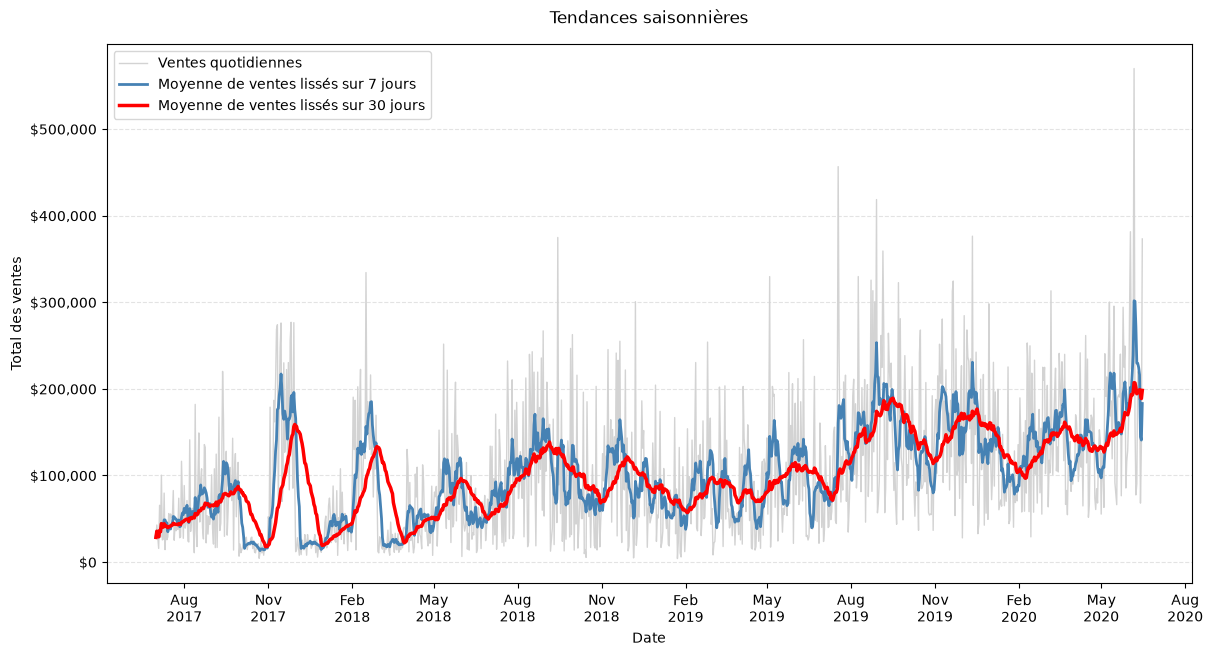

In [110]:
# Graphique
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(14, 7))

# Ventes quotidiennes
ax.plot(
    daily_sales.index,
    daily_sales["Sales Amount"],
    label="Ventes quotidiennes",
    color="lightgray",
    linewidth=1
)

# Tendances (7 et 30 jours)
ax.plot(
    daily_sales.index,
    daily_sales["Average Sales past 7 days"],
    label="Moyenne de ventes lissés sur 7 jours",
    color="steelblue",
    linewidth=2
)

ax.plot(
    daily_sales.index,
    daily_sales["Average Sales past 30 days"],
    label="Moyenne de ventes lissés sur 30 jours",
    color="red",
    linewidth=2.5
)

ax.set_title("Tendances saisonnières", pad=15)
ax.set_xlabel("Date")
ax.set_ylabel("Total des ventes")

# Formattage de la valeur des ventes
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))

# Formattage de la valeur des ventes
ax.yaxis.set_major_formatter(tick.StrMethodFormatter("${x:,.0f}"))

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend()
# Sauvegarde
plt.savefig("./output/EDA/tendances_ventes.png", dpi=300, bbox_inches="tight")

# Affichage
plt.show()

> Générez des tableaux croisés dynamiques (pivot tables) pour analyser les
ventes par différentes dimensions (par exemple, somme des ventes par produit
et par territoire).


In [113]:
df_sales

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,...,Expected Sales Amount,Valid Sales Amount,Expected Total Product Cost,Valid Total Product Cost,Price ratio,Margin
0,43659001,676,-1,349,20170702,20170712,...,2024.994,True,1898.0944,True,1.07,126.90
1,43659002,676,-1,350,20170702,20170712,...,6074.982,True,5694.2832,True,1.07,380.70
2,43659003,676,-1,351,20170702,20170712,...,2024.994,True,1898.0944,True,1.07,126.90
3,43659004,676,-1,344,20170702,20170712,...,2039.994,True,1912.1544,True,1.07,127.84
4,43659005,676,-1,345,20170702,20170712,...,2039.994,True,1912.1544,True,1.07,127.84
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121248,75122001,-1,15868,485,20200615,20200625,...,21.980,True,8.2205,True,2.67,13.76
121249,75122002,-1,15868,225,20200615,20200625,...,8.990,True,6.9223,True,1.30,2.07
121250,75123001,-1,18759,485,20200615,20200625,...,21.980,True,8.2205,True,2.67,13.76
121251,75123002,-1,18759,486,20200615,20200625,...,159.000,True,59.4660,True,2.67,99.53


In [114]:
sales_analysis = (
    df_sales.merge(
        df_products[["ProductKey", "Product"]],
        on="ProductKey",
        how="left"
    )
    .merge(
        df_territories[["SalesTerritoryKey", "Country", "Region"]],
        on="SalesTerritoryKey",
        how="left"
    )
)

sales_analysis["Territory"] = sales_analysis["Country"] + " - " + sales_analysis["Region"]

In [115]:
pivot_table_product_territory = pd.pivot_table(
    sales_analysis,
    index="Product",        # Un produit par ligne
    columns="Territory",    # Un territoire par colonne
    values="Sales Amount",  # Valeur
    aggfunc="sum",          # Somme des ventes
    fill_value=0,           # 0 si aucune vente
    margins=True,           # Ajoute les totaux
    margins_name="Total"
)

pivot_table_product_territory

Territory,Australia - Australia,Canada - Canada,France - France,Germany - Germany,United Kingdom - United Kingdom,United States - Central,United States - Northeast,United States - Northwest,United States - Southeast,United States - Southwest,Total
Product,,,,,,,,,,,
AWC Logo Cap,4.828754e+03,9.326738e+03,3.933437e+03,3.919969e+03,4.829039e+03,3.015188e+03,2.680252e+03,5.652341e+03,2.774551e+03,1.026918e+04,5.122945e+04
All-Purpose Bike Stand,1.033500e+04,5.088000e+03,3.021000e+03,3.180000e+03,4.452000e+03,0.000000e+00,0.000000e+00,5.724000e+03,0.000000e+00,7.791000e+03,3.959100e+04
Bike Wash - Dissolver,2.286420e+03,3.268596e+03,1.459575e+03,1.378689e+03,1.587966e+03,8.161661e+02,1.110595e+03,2.407187e+03,8.594858e+02,3.232293e+03,1.840697e+04
Cable Lock,0.000000e+00,4.210240e+03,1.050000e+03,0.000000e+00,7.350000e+02,1.620000e+03,1.455000e+03,1.560000e+03,1.295520e+03,4.299460e+03,1.622522e+04
Chain,8.500800e+02,1.141536e+03,1.231653e+03,5.221920e+02,6.602450e+02,5.343360e+02,6.436320e+02,1.663728e+03,2.671680e+02,1.863141e+03,9.377710e+03
...,...,...,...,...,...,...,...,...,...,...,...
"Women's Mountain Shorts, S",4.493358e+03,2.813724e+04,9.522426e+03,2.857048e+03,1.017598e+04,1.051162e+04,6.644144e+03,2.782488e+04,1.400869e+04,2.298875e+04,1.371641e+05
"Women's Tights, L",0.000000e+00,2.290443e+04,5.272044e+03,0.000000e+00,4.828546e+03,9.304249e+03,9.197644e+03,9.349243e+03,8.757880e+03,2.394043e+04,9.355446e+04
"Women's Tights, M",0.000000e+00,4.499400e+03,1.259832e+03,0.000000e+00,8.548860e+02,5.399280e+02,2.249700e+03,2.069724e+03,1.259832e+03,4.994334e+03,1.772764e+04


# Jour 2 : Analyse avancée et visualisation avec Mathplotlib


## 1. Analyse statistique des données
> Affichez les informations statistiques classiques des ventes (moyenne,
médiane, écart-type, minimum, maximum, premier quartile et troisième
quartile) pour chaque territoire.


In [116]:
df_sales_territories

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,...,Price ratio,Margin,Country,Group,Region,Territory Label
0,43659001,676,-1,349,20170702,20170712,...,1.07,126.90,United States,North America,Southeast,United States\nS...
1,43659002,676,-1,350,20170702,20170712,...,1.07,380.70,United States,North America,Southeast,United States\nS...
2,43659003,676,-1,351,20170702,20170712,...,1.07,126.90,United States,North America,Southeast,United States\nS...
3,43659004,676,-1,344,20170702,20170712,...,1.07,127.84,United States,North America,Southeast,United States\nS...
4,43659005,676,-1,345,20170702,20170712,...,1.07,127.84,United States,North America,Southeast,United States\nS...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121248,75122001,-1,15868,485,20200615,20200625,...,2.67,13.76,Canada,North America,Canada,Canada\nCanada
121249,75122002,-1,15868,225,20200615,20200625,...,1.30,2.07,Canada,North America,Canada,Canada\nCanada
121250,75123001,-1,18759,485,20200615,20200625,...,2.67,13.76,Canada,North America,Canada,Canada\nCanada
121251,75123002,-1,18759,486,20200615,20200625,...,2.67,99.53,Canada,North America,Canada,Canada\nCanada


In [122]:
stats_sales_by_territory = (
    df_sales_territories
    .dropna(subset=["Territory Label", "Sales Amount"])
    .groupby("Territory Label")["Sales Amount"]
    .describe()
    .rename(columns={
        "25%": "q1",
        "50%": "median",
        "75%": "q3",
    })
    .round(2)
)

stats_sales_by_territory

,count,mean,std,min,q1,median,q3,max
Territory Label,,,,,,,,
Australia\nAustralia,15058.0,707.62,1119.90,2.29,8.99,35.00,1120.49,17616.37
Canada\nCanada,19064.0,857.94,1688.14,1.37,26.72,127.80,890.82,23020.13
France\nFrance,9088.0,797.93,1583.30,2.29,21.49,64.79,923.39,23667.85
Germany\nGermany,7464.0,653.58,1263.61,1.37,8.99,35.00,769.49,19930.83
United Kingdom\nUnited Kingdom,10426.0,735.73,1402.64,1.37,9.99,53.99,890.82,22422.18
United States\nCentral,5832.0,1356.14,2221.75,1.37,125.42,469.79,1619.97,27055.76
United States\nNortheast,5836.0,1189.06,1753.82,1.37,136.76,449.94,1430.44,14880.00
United States\nNorthwest,16865.0,953.75,1916.08,1.37,24.29,86.52,1120.49,21101.79
United States\nSoutheast,5976.0,1318.55,2175.63,1.37,115.36,445.41,1471.70,24938.48


> Calculez la corrélation entre différentes variables :
Entre les ventes totales et les profits.
Entre le coût total et la marge.

In [123]:
df_sales_territories.info()

<class 'pandas.DataFrame'>
RangeIndex: 121253 entries, 0 to 121252
Data columns (total 27 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   SalesOrderLineKey            121253 non-null  int64  
 1   ResellerKey                  121253 non-null  int64  
 2   CustomerKey                  121253 non-null  int64  
 3   ProductKey                   121253 non-null  int64  
 4   OrderDateKey                 121253 non-null  int64  
 5   DueDateKey                   121253 non-null  int64  
 6   ShipDateKey                  121253 non-null  Int64  
 7   SalesTerritoryKey            121253 non-null  int64  
 8   Order Quantity               121253 non-null  int64  
 9   Unit Price                   121253 non-null  float64
 10  Extended Amount              121253 non-null  float64
 11  Unit Price Discount Pct      121253 non-null  int64  
 12  Product Standard Cost        121253 non-null  float64
 13  Total Prod

In [126]:
corr_sales_profit = df_sales_territories["Sales Amount"].corr(df_sales_territories["Margin"])
corr_cost_margin = df_sales_territories["Total Product Cost"].corr(df_sales_territories["Margin"])

print(f"Corrélation ventes totales / profits : {corr_sales_profit:.3f}")
print(f"Corrélation ventes totales / marge : {corr_cost_margin:.3f}")


Corrélation ventes totales / profits : 0.201
Corrélation ventes totales / marge : -0.036


Proche de 1 : Les deux variables augmentent ensemble

Proche de 0 : Peu ou pas de relation linéaire

Proche de -1 : L'une augmente quand l'autre diminue
